# 11 Model Comparison

Compares every model on the same rows, labels and metrics, using the predictions each modelling notebook saved to `results/predictions/`. Nothing is retrained here.

| Model | Notebook | Looks at | Outputs |
|---|---|---|---|
| Text only | `06_text_model` | caption | `text_fake` |
| Image only | `07_image_model` | image | `image_fake` |
| Late fusion of the single-mode models | this notebook | both, separately | `is_fake` = noisy-OR of 07's `image_fake` and 06's `text_fake` |
| Early fusion | `09_multimodal_early_fusion` | both, jointly | `image_fake`, `text_fake`, `is_fake` |
| Stacking | `10_multimodal_stacking` | both, jointly | `image_fake`, `text_fake`, `is_fake` |

**The main question:** does looking at the image and caption *together* (09, 10) beat combining two separate single-mode models (late fusion)? The early-fusion and stacking models include image–caption interactions.

**Evaluation rules** (as in every modelling notebook, via `src/evaluation.py`):
- Every score is evaluated against the target it predicts. `is_fake` combines `image_fake` and `text_fake` with the same noisy-OR rule for every model.
- Two thresholds per model and target, both chosen on **validation**: the best F1, and one that flags at most 1% of that target's validation negatives. The same thresholds are then applied unchanged to test, where the false-positive rate may differ.
- The test set is evaluated once, at the end (`RUN_TEST`).

## 0. Setup

In [32]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import binary_metrics, best_f1_threshold, combine_fake_score, detection_rate_by_type, prevalence_table

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions"

TARGETS = ["is_fake", "image_fake", "text_fake"]
TARGET_FPR = 0.01

# Leave False while developing. Set True once, at the end, to report final test results.
RUN_TEST = True

sns.set_theme(style="whitegrid")

## 1. Load Predictions

Each modelling notebook saves `<prefix>_<split>.parquet` with `row_id` and its probability columns. A model whose file is missing is skipped with a message, so this notebook runs with whatever has been saved so far.

In [33]:
LABELS = ["row_id", "id", "fake_cls", "is_fake", "image_fake", "text_fake"]

# Saved predictions of each model: file prefix and the probability columns it provides
SOURCES = {
    "Text only (06)": ("text_model", ["p_text_fake"]),
    "Image only (07)": ("image_model", ["p_image_fake"]),
    "Early fusion (09)": ("early_fusion", ["p_image_fake", "p_text_fake"]),
    "Stacking (10)": ("multimodal_stacking", ["p_image_fake", "p_text_fake"]),
}
LATE_FUSION = "Late fusion: 07 image + 06 text"


def load_scores(split):
    """Labels of a split and every available model's scores on it, as {model: {target: scores}}."""
    labels = pd.read_parquet(PROCESSED_DIR / f"{split}.parquet", columns=LABELS)
    loaded = {}
    for model, (prefix, cols) in SOURCES.items():
        path = PREDICTIONS_DIR / f"{prefix}_{split}.parquet"
        if not path.exists():
            print(f"{model}: {path.relative_to(PROJECT_ROOT)} not found, skipped")
            continue
        pred = labels[["row_id"]].merge(pd.read_parquet(path, columns=["row_id"] + cols),
                                        on="row_id", how="left", validate="one_to_one")
        assert pred[cols].notna().all().all(), f"{model}: no prediction for some {split} rows"
        loaded[model] = {c.removeprefix("p_"): pred[c].to_numpy() for c in cols}

    scores = {}
    for model in ["Text only (06)", "Image only (07)", LATE_FUSION, "Early fusion (09)", "Stacking (10)"]:
        if model == LATE_FUSION:
            if "Text only (06)" in loaded and "Image only (07)" in loaded:
                scores[model] = {"image_fake": loaded["Image only (07)"]["image_fake"],
                                 "text_fake": loaded["Text only (06)"]["text_fake"]}
        elif model in loaded:
            scores[model] = loaded[model]
    # Pair-level score: fake if either the image or the caption is, the same rule for every model
    for s in scores.values():
        if {"image_fake", "text_fake"} <= s.keys():
            s["is_fake"] = combine_fake_score(s["image_fake"], s["text_fake"])
    # Late fusion's image and caption scores are 07's and 06's own, already reported under those models
    if LATE_FUSION in scores:
        scores[LATE_FUSION] = {"is_fake": scores[LATE_FUSION]["is_fake"]}
    return labels, scores


val, val_scores = load_scores("validation")
pd.DataFrame({m: {t: t in s for t in TARGETS} for m, s in val_scores.items()}).T

,is_fake,image_fake,text_fake
Text only (06),False,False,True
Image only (07),False,True,False
Late fusion: 07 image + 06 text,True,False,False
Early fusion (09),True,True,True
Stacking (10),True,True,True


## 2. Thresholds (validation)

For each model and target: the best-F1 threshold, and a threshold allowing at most 1% of that target's validation negatives to be flagged. Tied scores at the cutoff are excluded together, so the achieved rate can be below 1%. Thresholds are fixed before test evaluation.


In [34]:
def fpr_threshold(y, score, rate=TARGET_FPR):
    """Conservative validation cutoff for decisions made with score >= threshold."""
    negative_scores = np.sort(np.asarray(score)[np.asarray(y) == 0])
    if not len(negative_scores) or not np.isfinite(negative_scores).all() or not 0 <= rate < 1:
        raise ValueError("Finite negative scores and a rate in [0, 1) are required")
    allowed = int(np.floor(rate * len(negative_scores)))
    cutoff = negative_scores[len(negative_scores) - allowed - 1]
    # Step in the scores' own floating dtype, so float32 comparisons also exclude ties.
    return float(np.nextafter(cutoff, np.inf, dtype=negative_scores.dtype))


thresholds = {}
for model, s in val_scores.items():
    for target, score in s.items():
        thresholds[model, target, "F1"] = best_f1_threshold(val[target], score)
        thresholds[model, target, "FPR1"] = fpr_threshold(val[target], score)

pd.Series(thresholds).unstack().round(3)

F1   FPR1
Early fusion (09)               image_fake  0.345  0.918
                                is_fake     0.390  0.953
                                text_fake   0.440  0.873
Image only (07)                 image_fake  0.411  0.936
Late fusion: 07 image + 06 text is_fake     0.392  0.964
Stacking (10)                   image_fake  0.391  0.914
                                is_fake     0.404  0.945
                                text_fake   0.417  0.786
Text only (06)                  text_fake   0.198  0.772

## 3. Results by Target

Threshold-free metrics (ROC-AUC, PR-AUC, EER), accuracy, precision, recall and F1 at the validation-selected F1 threshold, and recall at thresholds allowing at most 1% validation false positives. The achieved false-positive rates are reported explicitly.


In [35]:
METRICS = ["AUC", "PR-AUC", "EER", "ACC", "Precision", "Recall", "F1"]


def results_table(labels, scores):
    rows = []
    for target in TARGETS:
        y = labels[target].to_numpy()
        for model, s in scores.items():
            if target not in s:
                continue
            m = binary_metrics(y, s[target], thresholds[model, target, "F1"])
            strict = s[target] >= thresholds[model, target, "FPR1"]
            rows.append({"target": target, "model": model, **{k: m[k] for k in METRICS},
                         "FPR at 1% threshold": strict[y == 0].mean(), "Recall at 1% FPR": strict[y == 1].mean()})
    return pd.DataFrame(rows).set_index(["target", "model"]).rename(columns={"AUC": "ROC-AUC", "ACC": "Accuracy"})


results_val = results_table(val, val_scores)
results_val.round(3)

ROC-AUC  PR-AUC    EER  Accuracy  \
target     model                                                               
is_fake    Late fusion: 07 image + 06 text    0.805   0.893  0.277     0.739   
           Early fusion (09)                  0.817   0.906  0.273     0.735   
           Stacking (10)                      0.872   0.935  0.221     0.785   
image_fake Image only (07)                    0.848   0.873  0.244     0.742   
           Early fusion (09)                  0.797   0.832  0.291     0.688   
           Stacking (10)                      0.872   0.895  0.223     0.766   
text_fake  Text only (06)                     0.762   0.553  0.314     0.669   
           Early fusion (09)                  0.894   0.820  0.196     0.856   
           Stacking (10)                      0.910   0.840  0.176     0.866   

                                            Precision  Recall     F1  \
target     model                                                       
is_fake    Late fusion: 07 image + 06 text      0.743   0.926  0.825   
           Early fusion (09)                    0.735   0.938  0.824   
           Stacking (10)                        0.790   0.919  0.850   
image_fake Image only (07)                      0.709   0.887  0.788   
           Early fusion (09)                    0.652   0.906  0.758   
           Stacking (10)                        0.735   0.886  0.803   
text_fake  Text only (06)                       0.429   0.752  0.546   
           Early fusion (09)                    0.757   0.671  0.712   
           Stacking (10)                        0.773   0.700  0.735   

                                            FPR at 1% threshold  \
target     model                                                  
is_fake    Late fusion: 07 image + 06 text                 0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   
image_fake Image only (07)                                 0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   
text_fake  Text only (06)                                  0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   

                                            Recall at 1% FPR  
target     model                                              
is_fake    Late fusion: 07 image + 06 text             0.221  
           Early fusion (09)                           0.345  
           Stacking (10)                               0.409  
image_fake Image only (07)                             0.282  
           Early fusion (09)                           0.242  
           Stacking (10)                               0.355  
text_fake  Text only (06)                              0.109  
           Early fusion (09)                           0.469  
           Stacking (10)                               0.489

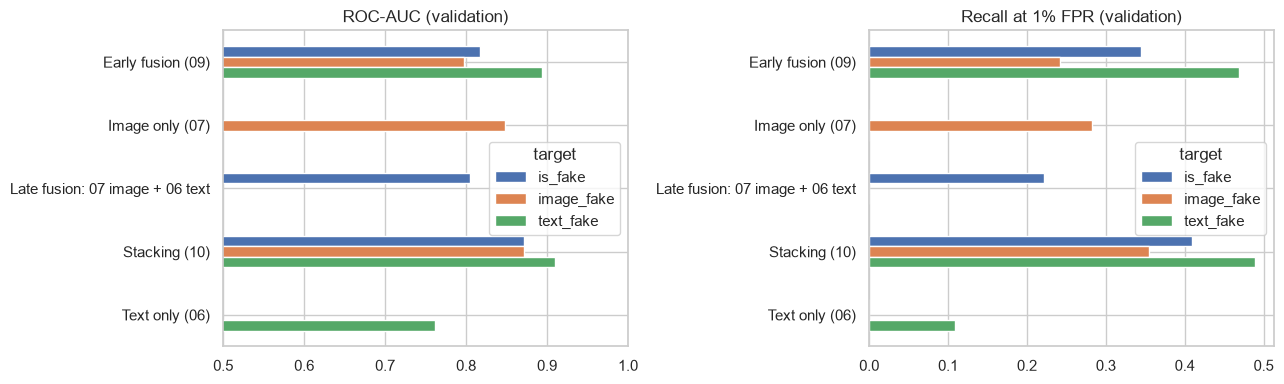

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["ROC-AUC", "Recall at 1% FPR"]):
    results_val[metric].unstack("target")[TARGETS].plot.barh(ax=ax)
    ax.set_title(f"{metric} (validation)")
    ax.set_ylabel("")
    ax.invert_yaxis()
axes[0].set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

### 3.1 Overall Detection: Confusion Matrices

Late fusion, early fusion and stacking predict the same `is_fake` target for an **image–caption pair**. A **genuine pair** has neither an edited image nor an edited caption. A **manipulated pair** has an edited image, an edited caption, or both; the matrix does not identify which component was edited. Each matrix uses that model's best-F1 threshold selected on validation. Cells show counts and percentages within the true class; the common colour scale shows those percentages. False positives are genuine pairs flagged as manipulated; false negatives are manipulated pairs missed by the model.


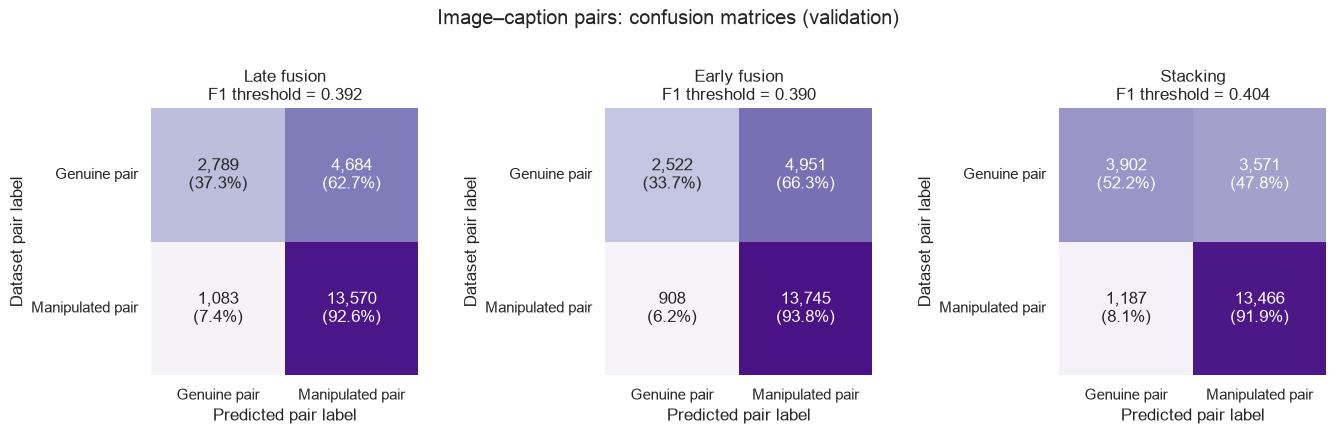

In [37]:
def plot_overall_confusion_matrices(labels, scores, split):
    models = [(name, s["is_fake"]) for name, s in scores.items() if "is_fake" in s]
    if not models:
        print(f"No overall-detection predictions available for {split}.")
        return
    names = {LATE_FUSION: "Late fusion", "Early fusion (09)": "Early fusion", "Stacking (10)": "Stacking"}
    fig, axes = plt.subplots(1, len(models), figsize=(4.6 * len(models), 4.2), squeeze=False)
    for ax, (model, score) in zip(axes[0], models):
        threshold = thresholds[model, "is_fake", "F1"]
        counts = confusion_matrix(labels["is_fake"], score >= threshold, labels=[0, 1])
        row_totals = counts.sum(axis=1, keepdims=True)
        proportions = np.divide(counts, row_totals, out=np.zeros_like(counts, dtype=float), where=row_totals != 0)
        annotations = np.array([[f"{counts[r, c]:,}\n({proportions[r, c]:.1%})" for c in range(2)] for r in range(2)])
        sns.heatmap(proportions, annot=annotations, fmt="", cmap="Purples", vmin=0, vmax=1,
                    cbar=False, square=True, xticklabels=["Genuine pair", "Manipulated pair"],
                    yticklabels=["Genuine pair", "Manipulated pair"], ax=ax)
        ax.set_title(f"{names.get(model, model)}\nF1 threshold = {threshold:.3f}")
        ax.set_xlabel("Predicted pair label")
        ax.set_ylabel("Dataset pair label")
        ax.tick_params(axis="y", labelrotation=0)
    fig.suptitle(f"Image–caption pairs: confusion matrices ({split})", y=1.02)
    fig.tight_layout()
    plt.show()


plot_overall_confusion_matrices(val, val_scores, "validation")


### 3.2 Overall Detection: ROC Curves

The curves compare the share of manipulated image–caption pairs detected against the share of genuine pairs incorrectly flagged, across thresholds. Manipulation can affect the image, caption, or both. Higher curves and ROC-AUC indicate better ranking; the dashed diagonal represents random ranking. Unlike the confusion matrices, these curves do not use a single selected threshold.


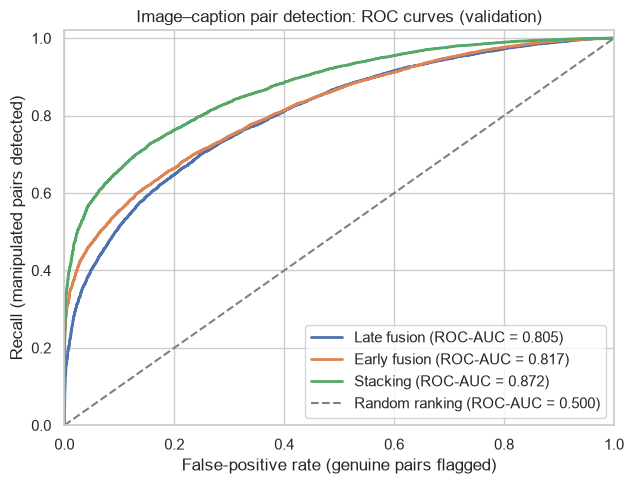

In [38]:
def plot_overall_roc(labels, scores, split):
    models = [(name, s["is_fake"]) for name, s in scores.items() if "is_fake" in s]
    if not models:
        print(f"No overall-detection predictions available for {split}.")
        return
    names = {LATE_FUSION: "Late fusion", "Early fusion (09)": "Early fusion", "Stacking (10)": "Stacking"}
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for model, score in models:
        fpr, tpr, _ = roc_curve(labels["is_fake"], score)
        auc = roc_auc_score(labels["is_fake"], score)
        ax.plot(fpr, tpr, linewidth=2, label=f"{names.get(model, model)} (ROC-AUC = {auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random ranking (ROC-AUC = 0.500)")
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False-positive rate (genuine pairs flagged)", ylabel="Recall (manipulated pairs detected)",
           title=f"Image–caption pair detection: ROC curves ({split})")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()


plot_overall_roc(val, val_scores, "validation")


## 4. What Each Model Catches

Share of each manipulation class flagged by the pair-level `is_fake` score at its low-false-positive threshold. For `orig` this is the measured false-positive rate, at most 1% on validation.


In [39]:
by_type = pd.DataFrame({
    model: detection_rate_by_type(val, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
    for model, s in val_scores.items() if "is_fake" in s
})
by_type.loc[by_type.mean(axis=1).sort_values().index].round(3)

,Late fusion: 07 image + 06 text,Early fusion (09),Stacking (10)
fake_cls,,,
orig,0.010,0.010,0.010
text_attribute,0.139,0.063,0.046
face_swap,0.235,0.189,0.322
face_attribute,0.239,0.245,0.312
face_swap&text_attribute,0.426,0.293,0.424
text_swap,0.011,0.628,0.563
face_attribute&text_attribute,0.458,0.345,0.435
face_swap&text_swap,0.278,0.731,0.773
face_attribute&text_swap,0.258,0.783,0.787


## 5. Realistic Prevalence

Validation is ~66% fake. Per 100,000 posts at a 1% fake rate, using each model's `is_fake` 1% false-alarm threshold: how many alerts reviewers would see and how many fakes they would catch.

In [40]:
pd.concat({
    model: prevalence_table(val["is_fake"], s["is_fake"], thresholds[model, "is_fake", "FPR1"], prevalences=[0.01])
    for model, s in val_scores.items() if "is_fake" in s
}).droplevel("fake_rate").round(3)

,fakes_per_100k,alerts,fakes_caught,false_alarms,precision,recall
Late fusion: 07 image + 06 text,1000.0,1201.376,221.047,980.329,0.184,0.221
Early fusion (09),1000.0,1325.105,344.776,980.329,0.260,0.345
Stacking (10),1000.0,1389.256,408.926,980.329,0.294,0.409


**Findings (validation, current saved predictions)**
- **Stacking has the highest overall ROC-AUC and F1.** `is_fake` ROC-AUC is 0.872 for stacking, 0.817 for early fusion and 0.805 for late fusion. Best-F1 scores are approximately 0.850, 0.824 and 0.825, respectively. Early fusion improves ranking over late fusion, but its F1 is slightly lower.
- **Early fusion and stacking catch more fakes under the low-false-positive constraint.** They detect approximately 34% and 41% of fake pairs, versus 22% for late fusion, at thresholds allowing at most 1% genuine validation false positives.
- **Swapped-caption detection improves.** Approximately 63% of `text_swap` pairs are caught by early fusion and 56% by stacking, versus 1% by late fusion at those thresholds. This supports the usefulness of image–caption information on this validation set; it does not establish that text-only detection is impossible.
- **Late fusion catches more sentiment edits at this operating point.** It flags approximately 14% of `text_attribute`-only pairs, versus 5–6% for the two other overall detectors. The 14% figure describes late fusion's `is_fake` decisions, not the text-only model's `text_fake` decisions.

These are descriptive validation comparisons. The models differ in inputs and architecture, so the results do not isolate the cause of a gain or establish statistical significance or generalisation beyond DGM4.


## 6. Test Evaluation (run once, at the end)

Uses the thresholds fixed on validation above. Each modelling notebook must first write its `<prefix>_test.parquet`; `10` writes it only once its own `RUN_TEST` is set.

ROC-AUC  PR-AUC    EER  Accuracy  \
target     model                                                               
is_fake    Late fusion: 07 image + 06 text    0.806   0.896  0.278     0.742   
           Early fusion (09)                  0.828   0.913  0.261     0.744   
           Stacking (10)                      0.879   0.940  0.214     0.794   
image_fake Image only (07)                    0.854   0.875  0.238     0.749   
           Early fusion (09)                  0.803   0.833  0.284     0.685   
           Stacking (10)                      0.878   0.897  0.217     0.771   
text_fake  Text only (06)                     0.766   0.584  0.306     0.662   
           Early fusion (09)                  0.903   0.840  0.185     0.857   
           Stacking (10)                      0.921   0.865  0.163     0.873   

                                            Precision  Recall     F1  \
target     model                                                       
is_fake    Late fusion: 07 image + 06 text      0.750   0.920  0.826   
           Early fusion (09)                    0.744   0.940  0.831   
           Stacking (10)                        0.801   0.920  0.856   
image_fake Image only (07)                      0.712   0.884  0.789   
           Early fusion (09)                    0.644   0.906  0.753   
           Stacking (10)                        0.738   0.882  0.804   
text_fake  Text only (06)                       0.443   0.745  0.556   
           Early fusion (09)                    0.776   0.698  0.735   
           Stacking (10)                        0.803   0.733  0.766   

                                            FPR at 1% threshold  \
target     model                                                  
is_fake    Late fusion: 07 image + 06 text                0.007   
           Early fusion (09)                              0.014   
           Stacking (10)                                  0.009   
image_fake Image only (07)                                0.008   
           Early fusion (09)                              0.010   
           Stacking (10)                                  0.007   
text_fake  Text only (06)                                 0.008   
           Early fusion (09)                              0.012   
           Stacking (10)                                  0.011   

                                            Recall at 1% FPR  
target     model                                              
is_fake    Late fusion: 07 image + 06 text             0.215  
           Early fusion (09)                           0.358  
           Stacking (10)                               0.415  
image_fake Image only (07)                             0.279  
           Early fusion (09)                           0.243  
           Stacking (10)                               0.357  
text_fake  Text only (06)                              0.098  
           Early fusion (09)                           0.491  
           Stacking (10)                               0.511

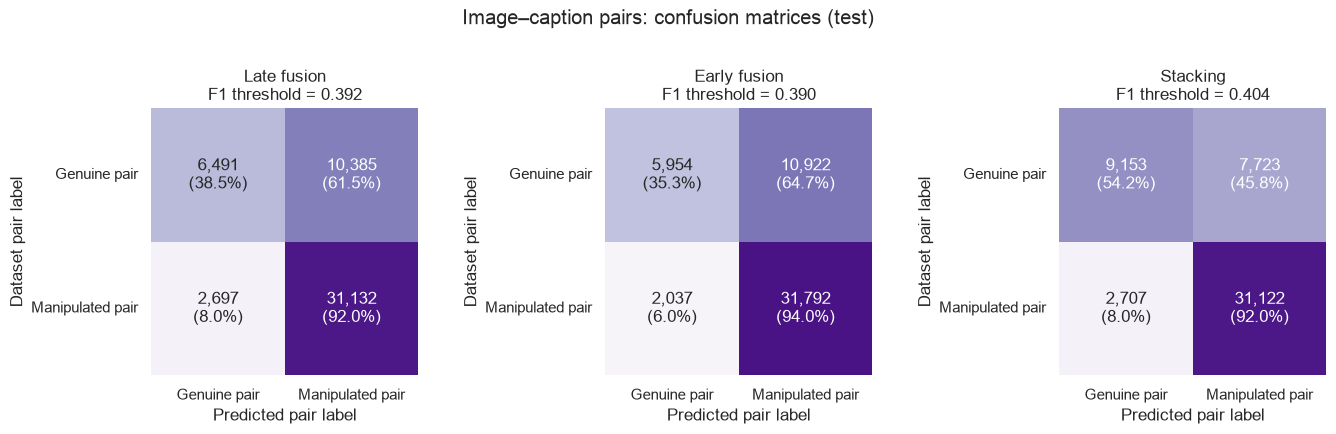

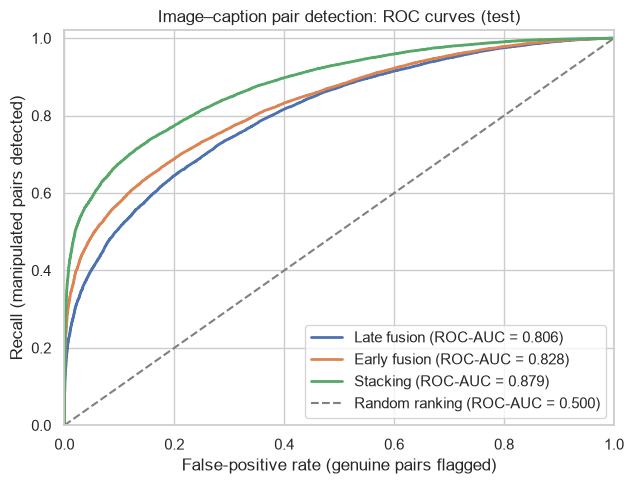

,Late fusion: 07 image + 06 text,Early fusion (09),Stacking (10)
fake_cls,,,
face_attribute,0.237,0.238,0.322
face_attribute&text_attribute,0.442,0.368,0.453
face_attribute&text_swap,0.247,0.746,0.743
face_swap,0.235,0.189,0.320
face_swap&text_attribute,0.436,0.308,0.431
face_swap&text_swap,0.284,0.735,0.765
orig,0.007,0.014,0.009
text_attribute,0.153,0.071,0.048
text_swap,0.008,0.634,0.545


In [41]:
if RUN_TEST:
    test, test_scores = load_scores("test")
    test_scores = {m: s for m, s in test_scores.items() if m in val_scores}
    display(results_table(test, test_scores).round(3))
    plot_overall_confusion_matrices(test, test_scores, "test")
    plot_overall_roc(test, test_scores, "test")
    display(pd.DataFrame({
        model: detection_rate_by_type(test, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
        for model, s in test_scores.items() if "is_fake" in s
    }).round(3))
else:
    print("RUN_TEST is False: test set not evaluated.")